# primus-paleo — 02: histories, scenarios, and under the hood

Notebook 01 used a sample sitting at a fixed depth under today's flux. Real samples have a **history**, and the
point of a cosmic-ray paleo-detector is to read a **flux scenario** out of it. The knobs:

| knob | what it is | where |
|---|---|---|
| overburden history | rock/water above the sample vs time | `overburden_history=` dict |
| flux history | baseline + supernovae + geomagnetic excursions | `pp.FluxHistory(events=, excursions=)` |
| exposure window | which part of the history we count | `exposure_window_kyr=` |
| annealing (**experimental**) | track shortening/fading with time and temperature | `annealing=` |

**Running example:** Messinian halite in the *desiccation* scenario (Caccianiga et al., PRD 110 (2024) L121301;
the full analysis is `analysis/MSC_analysis_new.ipynb`).

Creating new flux templates and new materials (MCEq, Geant4) is in notebook 03.
⏱ marks the slow cells, ~45 min in total on a laptop. Each slow cell saves its result in `demo_cache/` and loads it
on later runs; set `RERUN = True` in the first cell to recompute.

In [ ]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import primus_paleo as pp

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "legend.frameon": False, "font.size": 11})
Path("figures").mkdir(exist_ok=True)          # slide-ready PNGs are saved here

RERUN = False                                  # True: recompute every slow cell and overwrite its file
CACHE = Path("demo_cache"); CACHE.mkdir(exist_ok=True)

print("primus_paleo", pp.__version__)
pp.describe()

primus_paleo 0.1.0
data root           /home/claudio/primus-paleo/Data  (ok)
mineral library     /home/claudio/primus-paleo/Data/mineral_library.yaml  (ok)
flux templates      /home/claudio/primus-paleo/Data/flux_data  (ok)
Geant4 outputs      /home/claudio/primus-paleo/Data/Geant4_data  (ok)
Geant4 application  /home/claudio/primus-paleo/geant4/build/Run  (ok)


## 1. Anatomy of an overburden history

All lengths in **metres** of material, with a density, so the code works in m.w.e. Times are **local**
(0 = start of recording, `total_age_kyr` = today). Every key is optional:

| key | meaning |
|---|---|
| `initial_depth`, `initial_density_g_cm3` | what is above the sample at t = 0 (default 0.3 m of water) |
| `start_time_continuous_kyr`, `end_time_continuous_kyr`, `rate_continuous`, `density_continuous_g_cm3` | lists: continuous phases, rate in m/kyr (negative = erosion) |
| `time_discrete_kyr`, `overburden_discrete`, `density_discrete_g_cm3` | lists: sudden deposits (or removals, negative) |

A toy: 20 kyr at the surface, then 30 kyr of sedimentation, then a lava flow, then slow erosion.

Interpolating overburden history...
Time grid: 189 nodes over 0-100 kyr (105 uniform and breakpoint nodes, 84 added where the overburden or flux change; 0 flux events, 0 excursions)
Created paleo-detector Halite, species available for computation:
  mu+        energy from 0.001 to 171.9 GeV in 90 steps
  mu-        energy from 0.001 to 171.9 GeV in 90 steps
  neutron    energy from 0.001 to 171.9 GeV in 90 steps
  proton     energy from 0.001 to 171.9 GeV in 90 steps
  nu_mu      energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  anti_nu_mu energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  nu_e       energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  anti_nu_e  energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondarie

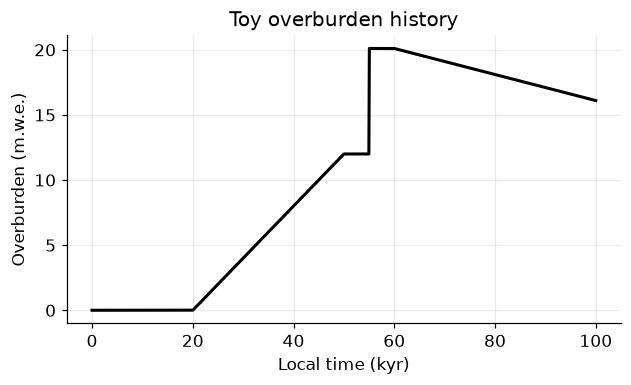

In [3]:
toy = {
    "initial_depth": 0.0,
    "start_time_continuous_kyr": [20.0, 60.0],
    "end_time_continuous_kyr":   [50.0, 100.0],
    "rate_continuous":           [0.2, -0.05],          # m/kyr: deposition, then erosion
    "density_continuous_g_cm3":  [2.0, 2.0],
    "time_discrete_kyr":      [55.0],
    "overburden_discrete":    [3.0],                    # a 3 m lava flow at 55 kyr
    "density_discrete_g_cm3": [2.7],
}
toy_det = pp.Paleodetector("Halite", total_age_kyr=100.0, overburden_history=toy)

t = np.linspace(0, 100, 1000)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
# _overburden_interpolator is internal (no public accessor yet): local time [kyr] -> overburden [m.w.e.]
ax.plot(t, toy_det._overburden_interpolator(t), color="k", lw=2)
ax.set(xlabel="Local time (kyr)", ylabel="Overburden (m.w.e.)", title="Toy overburden history")
plt.show()

## 2. The Messinian desiccation scenario

Halite deposited in a desiccated Mediterranean floor ~2 km below sea level (so with ~2.8 m.w.e. of *extra*
atmosphere), under a few metres of brine, then buried by the rest of the evaporite sequence and finally drowned by
the Zanclean flood. Local time 0 = 5.60 Ma, flood at 270 kyr, today at 5600 kyr.

In [4]:
AGE_KYR, FLOOD_KYR = 5600.0, 270.0
z_floor = 2000.0
air_mwe = 10.33 * (np.exp(z_floor / 8400.0) - 1.0)            # extra atmosphere, ~2.8 m.w.e.
D_brine, D_lake, D_flood, D_today = 5.0, 20.0, 2000.0, 1644.0
H_halite, H_IE, H_AE, H_PQ = 960.0, 480.0, 230.0, 450.0

desiccation = {
    "initial_depth": air_mwe + 1.2 * D_brine, "initial_density_g_cm3": 1.0,
    "start_time_continuous_kyr": [0.0, 50.0, 180.0, 270.0, 270.0],
    "end_time_continuous_kyr":   [50.0, 180.0, 270.0, 5600.0, 5600.0],
    "rate_continuous":           [H_halite / 50.0, H_IE / 130.0, H_AE / 90.0, H_PQ / 5330.0, (D_today - D_flood) / 5330.0],
    "density_continuous_g_cm3":  [2.16, 2.3, 2.3, 2.1, 1.03],
    "time_discrete_kyr":      [50.0, FLOOD_KYR, FLOOD_KYR, FLOOD_KYR],
    "overburden_discrete":    [D_lake - D_brine, -D_lake, -air_mwe, D_flood],
    "density_discrete_g_cm3": [1.2, 1.2, 1.0, 1.03],
}
det = pp.Paleodetector("Halite", total_age_kyr=AGE_KYR, overburden_history=desiccation)

Interpolating overburden history...
Time grid: 629 nodes over 0-5600 kyr (105 uniform and breakpoint nodes, 524 added where the overburden or flux change; 0 flux events, 0 excursions)
Created paleo-detector Halite, species available for computation:
  mu+        energy from 0.001 to 171.9 GeV in 90 steps
  mu-        energy from 0.001 to 171.9 GeV in 90 steps
  neutron    energy from 0.001 to 171.9 GeV in 90 steps
  proton     energy from 0.001 to 171.9 GeV in 90 steps
  nu_mu      energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  anti_nu_mu energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  nu_e       energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  anti_nu_e  energy from 0.05817 to 1311 GeV in 75 steps  (integrate_atmospheric_neutrinos; secondar

## 3. The rate along the history

`integrate_all_particles` is *rate on a time grid* + *trapezoid in time*. Asking for the rate ourselves with
`det.calculate_particle_signal_spectrum(t_kyr_array, ...)` lets us look inside: when were the tracks written?
The burial is fast, so the time grid is logarithmic.

In [ ]:
x_bins = pp.TRACK_LENGTH_BINS_NM
x_mid = np.sqrt(x_bins[1:] * x_bins[:-1]); width = np.diff(x_bins); dlog = np.diff(np.log10(x_bins))
t_grid = np.unique(np.concatenate([[0.0], np.geomspace(1e-3, AGE_KYR, 400), [FLOOD_KYR]]))

cache = CACHE / "02_rate_vs_time.npz"
if RERUN or not cache.exists():
    rate = {s: det.calculate_particle_signal_spectrum(t_grid, x_bins=x_bins, species=s)
            for s in det.available_species()}
    np.savez(cache, **rate)
else:
    rate = dict(np.load(cache))

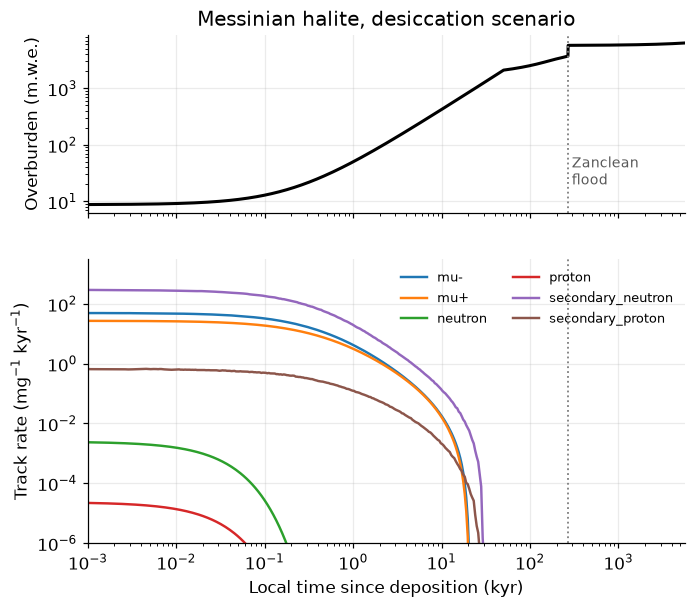

In [6]:
pos = t_grid > 0
fig, (a0, a1) = plt.subplots(2, 1, figsize=(7, 6), sharex=True, gridspec_kw={"height_ratios": [1, 1.6]})
a0.loglog(t_grid[pos], det._overburden_interpolator(t_grid[pos]), color="k", lw=2)   # internal, see section 1
a0.set(ylabel="Overburden (m.w.e.)", title="Messinian halite, desiccation scenario")
for s, r in rate.items():
    y = (r * width).sum(axis=1)[pos]
    a1.loglog(t_grid[pos], np.where(y > 0, y, np.nan), lw=1.6, label=s)
for a in (a0, a1):
    a.axvline(FLOOD_KYR, color="0.5", ls=":", lw=1.2)
a0.text(FLOOD_KYR * 1.1, 20, "Zanclean\nflood", fontsize=9, color="0.35")
a1.set(xlabel="Local time since deposition (kyr)", ylabel=r"Track rate (mg$^{-1}$ kyr$^{-1}$)", ylim=(1e-6, None),
       xlim=(t_grid[pos][0], AGE_KYR))
a1.legend(fontsize=8.5, ncol=2)
fig.savefig("figures/06_history_and_rate.png", dpi=200, bbox_inches="tight")
plt.show()

tracks written by t =      1 kyr:  78.7%
tracks written by t =      3 kyr:  94.4%
tracks written by t =     10 kyr:  99.6%
tracks written by t =    270 kyr: 100.0%
tracks written by t =   5600 kyr: 100.0%


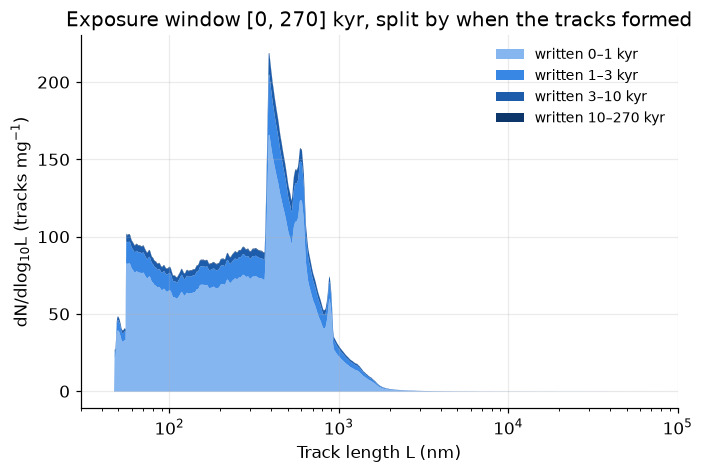

In [7]:
from scipy.integrate import cumulative_trapezoid

total_rate = sum((r * width).sum(axis=1) for r in rate.values())          # tracks/mg/kyr
written = cumulative_trapezoid(total_rate, t_grid, initial=0.0)
for tq in [1, 3, 10, FLOOD_KYR, AGE_KYR]:
    print(f"tracks written by t = {tq:6.0f} kyr: {np.interp(tq, t_grid, written) / written[-1]:6.1%}")

fig, ax = plt.subplots(figsize=(7, 4.4))
bottom = np.zeros_like(x_mid)
for (t0, t1), color in zip([(0, 1), (1, 3), (3, 10), (10, FLOOD_KYR)], ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]):
    sel = (t_grid >= t0) & (t_grid <= t1)
    part = sum(np.trapezoid(r[sel], t_grid[sel], axis=0) for r in rate.values()) * width / dlog
    ax.fill_between(x_mid, bottom, bottom + part, color=color, lw=0, label=f"written {t0:g}–{t1:g} kyr")
    bottom = bottom + part
ax.set(xscale="log", xlim=(30, 1e5), xlabel="Track length L (nm)", ylabel=r"dN/dlog$_{10}$L (tracks mg$^{-1}$)",
       title="Exposure window [0, 270] kyr, split by when the tracks formed")
ax.legend(fontsize=9)
fig.savefig("figures/07_spectrum_by_time_slice.png", dpi=200, bbox_inches="tight")
plt.show()

The halite is buried at ~40 m.w.e. per kyr: practically the whole cosmic-ray record is written in the first few
kyr, long before the flood closes the nominal exposure window.

Check against the one-liner for one species, `integrate_particle_signal_spectrum`, which uses the detector's own
adaptive time grid:

In [8]:
cache = CACHE / "02_check_mu+.npz"
if RERUN or not cache.exists():
    mu_plus = det.integrate_particle_signal_spectrum(x_bins=x_bins, species="mu+",
                                                     exposure_window_kyr=[0.0, FLOOD_KYR])
    np.savez(cache, counts=mu_plus)
else:
    mu_plus = np.load(cache)["counts"]

sel = t_grid <= FLOOD_KYR
ours = (np.trapezoid(rate["mu+"][sel], t_grid[sel], axis=0) * width).sum()
print(f"integrate_particle_signal_spectrum: {mu_plus.sum():.5g}   our rate + trapezoid: {ours:.5g} tracks/mg "
      f"({ours / mu_plus.sum() - 1:+.2%})")

integrate_particle_signal_spectrum: 12.703   our rate + trapezoid: 12.703 tracks/mg (-0.00%)


## 4. Flux scenarios: a nearby supernova

A `FluxHistory` is a baseline plus **events** (transient templates added on top) and **excursions** (periods with a
different geomagnetic cutoff). The flux clock runs **0 = present, negative = past**; the detector converts it
(local 0 ↔ −`total_age_kyr`).

Here: a supernova at 100 pc, exploding 25 kyr before the halite started to form (template `SN_100.0_5.0GV`,
already in `Data/flux_data`; building new templates is in notebook 03).

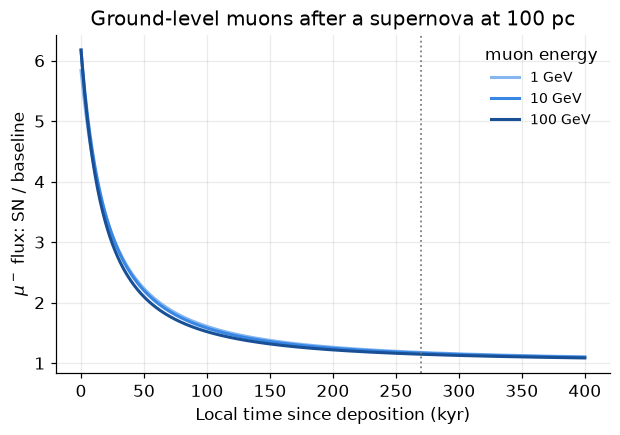

In [9]:
sn = pp.FluxHistory(events=[{"start_time_kyr": -AGE_KYR - 25.0, "template": {"kind": "SN", "distance_pc": 100.0},
                             "label": "SN 100 pc"}])
baseline = pp.FluxHistory()

t_flux = -AGE_KYR + np.linspace(0, 400, 401)        # flux clock
fig, ax = plt.subplots(figsize=(6.5, 4))
for energy, color in [(1.0, "#86b6ef"), (10.0, "#3987e5"), (100.0, "#184f95")]:
    E = np.full_like(t_flux, energy)
    ax.plot(t_flux + AGE_KYR, sn.flux("mu-", E, t_flux) / baseline.flux("mu-", E, t_flux), color=color, lw=2,
            label=f"{energy:g} GeV")
ax.axvline(FLOOD_KYR, color="0.5", ls=":", lw=1.2)
ax.set(xlabel="Local time since deposition (kyr)", ylabel=r"$\mu^-$ flux: SN / baseline",
       title="Ground-level muons after a supernova at 100 pc")
ax.legend(title="muon energy", fontsize=9)
fig.savefig("figures/08_sn_flux_ratio.png", dpi=200, bbox_inches="tight")
plt.show()

`integrate_all_particles(..., flux_history=...)` sets the flux history of the detector and integrates.
Note that it **stays set**: the second call puts the baseline back.

In [10]:
cache_sn, cache_base = CACHE / "02_supernova.npz", CACHE / "02_baseline.npz"
if RERUN or not (cache_sn.exists() and cache_base.exists()):
    _, cr_sn = det.integrate_all_particles(x_bins=x_bins, exposure_window_kyr=[0.0, FLOOD_KYR], flux_history=sn)
    _, cr_base = det.integrate_all_particles(x_bins=x_bins, exposure_window_kyr=[0.0, FLOOD_KYR],
                                             flux_history=baseline)
    np.savez(cache_sn, **cr_sn)
    np.savez(cache_base, **cr_base)
else:
    cr_sn, cr_base = dict(np.load(cache_sn)), dict(np.load(cache_base))

print(f"tracks/mg before the flood: baseline {cr_base['total'].sum():.4g}, SN 100 pc {cr_sn['total'].sum():.4g} "
      f"(x{cr_sn['total'].sum() / cr_base['total'].sum():.2f})")

tracks/mg before the flood: baseline 130.5, SN 100 pc 784.9 (x6.02)


/tmp/ipykernel_16977/3149292713.py:6: RuntimeWarning: invalid value encountered in divide
  ax.stairs(np.where(base_c > 0, sn_c / base_c, np.nan), coarse, color="k", lw=2)


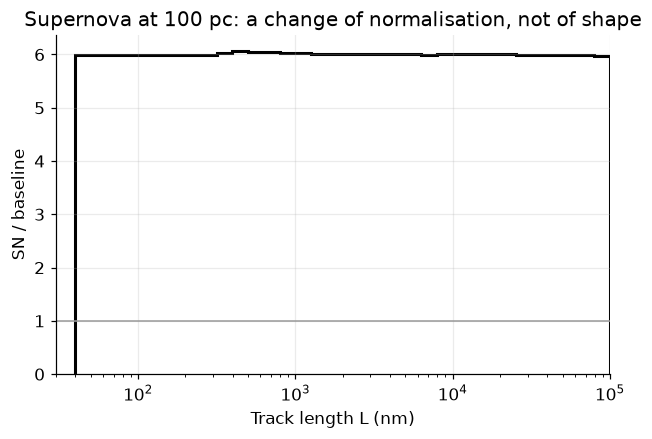

In [11]:
coarse = np.logspace(1.5, 5, 36)                   # coarser bins to read the ratio
base_c = pp.rebin_counts(cr_base["total"], x_bins, coarse)
sn_c = pp.rebin_counts(cr_sn["total"], x_bins, coarse)

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.stairs(np.where(base_c > 0, sn_c / base_c, np.nan), coarse, color="k", lw=2)
ax.axhline(1, color="0.6", lw=1)
ax.set(xscale="log", xlabel="Track length L (nm)", ylabel="SN / baseline", xlim=(30, 1e5), ylim=(0, None),
       title="Supernova at 100 pc: a change of normalisation, not of shape")
fig.savefig("figures/09_sn_over_baseline.png", dpi=200, bbox_inches="tight")
plt.show()

Because the halite is buried within a few kyr, it records only the first, brightest phase of the supernova, and
the boost is nearly the same at every track length: the scenario changes the **normalisation**, not the shape.
Telling scenarios apart therefore rests on the absolute track density, i.e. on knowing the overburden history —
or on comparing samples that recorded different time windows (the Chaîne des Puys chronosequence idea).

## 5. Geomagnetic excursions

An excursion swaps the rigidity cutoff over a time window (here the Laschamp event, ~41 ka, cutoff → 0 GV) for the
baseline and every active event. It needs templates at both cutoffs: the 1 km altitude set is in `Data/flux_data`
(the Chaîne des Puys sites); sea level at 0 GV would have to be built (notebook 03). A flux-level look: in these
templates the excursion acts on the nucleons below ~10 GeV (+14% at 1 km), while the muons above 1 GeV do not change.

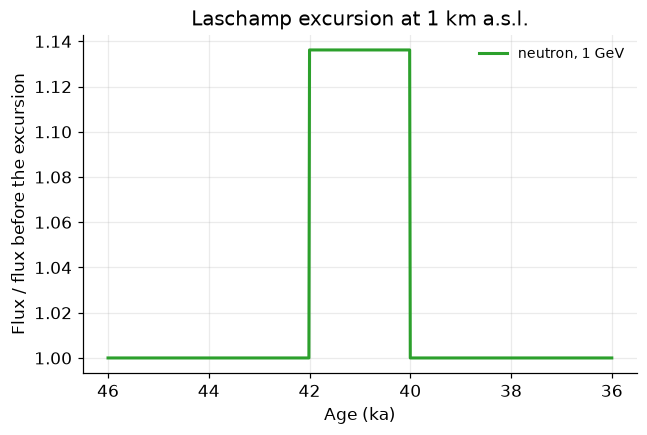

In [12]:
laschamp = pp.FluxHistory(baseline={"kind": "Baseline", "h_obs_km": 1.0},
                          excursions=[{"start_time_kyr": -42.0, "end_time_kyr": -40.0,
                                       "geomagnetic_cutoff": 0.0, "label": "Laschamp"}])
t_flux = np.linspace(-46, -36, 801)
fig, ax = plt.subplots(figsize=(6.5, 4))
energy = 1.0
f = laschamp.flux("neutron", np.full_like(t_flux, energy), t_flux)
ax.plot(-t_flux, f / f[0], color="C2", lw=2, label=f"neutron, {energy:g} GeV")
ax.invert_xaxis()
ax.set(xlabel="Age (ka)", ylabel="Flux / flux before the excursion", title="Laschamp excursion at 1 km a.s.l.")
ax.legend(fontsize=9)
fig.savefig("figures/10_laschamp_flux.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Under the hood

### 6a. Who makes the secondaries
The StdRock runs record every neutron and proton produced along 5 km of standard rock; the code folds them with
the flux into a production rate at each depth, then re-injects them (all generations).
`pp.plot_secondary_production` shows the raw material.

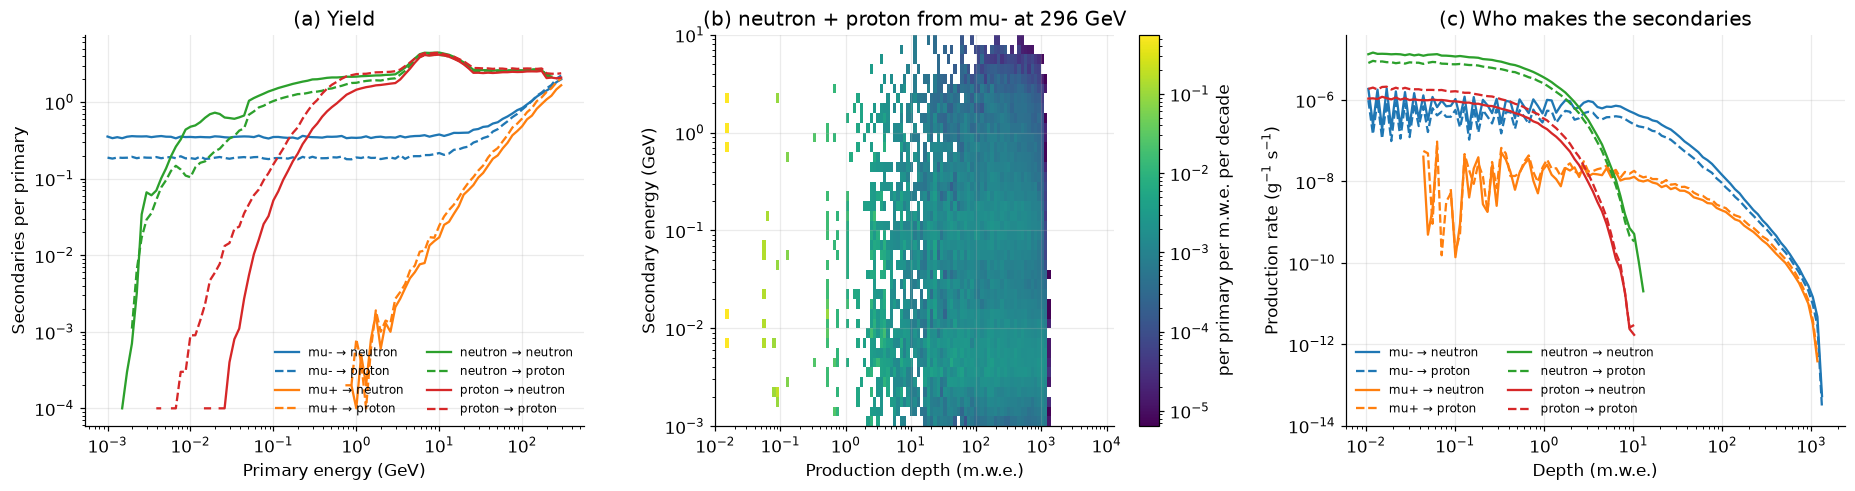

In [ ]:
fig, ax = pp.plot_secondary_production(det)
fig.savefig("figures/11_secondary_production.png", dpi=200, bbox_inches="tight")
plt.show()

### 6b. How deep each particle goes
`pp.interaction_profiles` gives, from the StdRock depth tables, where a particle of energy E interacts
(hadrons) or how its interactions are spread until it stops (muons, captures included).

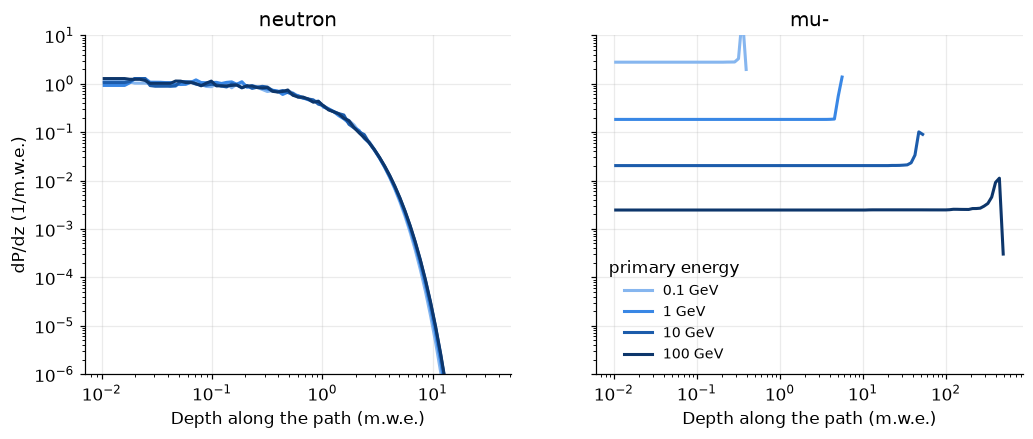

In [14]:
z_edges = np.logspace(-2, 3.5, 120); z_mid = np.sqrt(z_edges[1:] * z_edges[:-1])
energies = np.array([0.1, 1.0, 10.0, 100.0])
profiles = pp.interaction_profiles(det, energies, z_edges, species=("neutron", "mu-"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, s in zip(axes, ["neutron", "mu-"]):
    for j, (energy, color) in enumerate(zip(energies, ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])):
        y = profiles[s][:, j]
        ax.loglog(z_mid, np.where(y > 0, y, np.nan), color=color, lw=2, label=f"{energy:g} GeV")
    ax.set(xlabel="Depth along the path (m.w.e.)", title=s, ylim=(1e-6, 10))
axes[0].set_ylabel("dP/dz (1/m.w.e.)"); axes[1].legend(title="primary energy", fontsize=9)
fig.savefig("figures/12_interaction_profiles.png", dpi=200, bbox_inches="tight")
plt.show()

### 6c. What recoils, and how long a track it makes
`nucleus='all'` returns the rate for every fragment separately (here at deposition, t = 0, for the neutrons
made in the rock: later the sample is too deep for much to happen). Each recoil energy then becomes a length through
the mineral's range tables (`Data/Geant4_data/<mineral>/Range/DEDX_Z<z>_A<a>.txt`, from Geant4).

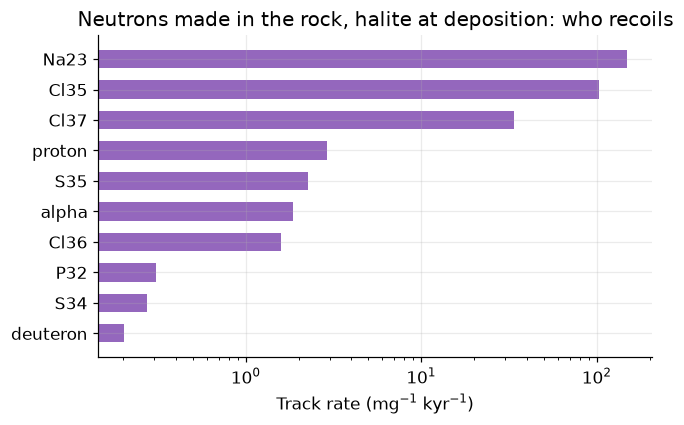

light ions (not counted by default): {'He3': '0.0251', 'He6': '0.00619', 'He8': '6.65e-06', 'alpha': '1.85', 'deuteron': '0.201', 'proton': '2.92', 'triton': '0.0512'}


In [ ]:
cache = CACHE / "02_fragments.npz"
if RERUN or not cache.exists():
    fragments = det.calculate_particle_signal_spectrum(np.array([0.0]), x_bins=x_bins, species="secondary_neutron",
                                                       nucleus="all")
    np.savez(cache, **fragments)
else:
    fragments = dict(np.load(cache))
rate_by_fragment = {k: (v[0] * width).sum() for k, v in fragments.items() if not k.startswith("total")}
top = sorted(((k, v) for k, v in rate_by_fragment.items() if v > 0), key=lambda kv: -kv[1])[:10]

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.barh([k for k, _ in top][::-1], [v for _, v in top][::-1], color="C4", height=0.6)
ax.set(xscale="log", xlabel=r"Track rate (mg$^{-1}$ kyr$^{-1}$)",
       title="Neutrons made in the rock, halite at deposition: who recoils")
fig.savefig("figures/13_recoil_nuclei.png", dpi=200, bbox_inches="tight")
plt.show()
print("light ions (not counted by default):",
      {k: f"{v:.3g}" for k, v in rate_by_fragment.items() if pp.is_light_ion(k) and v > 0})

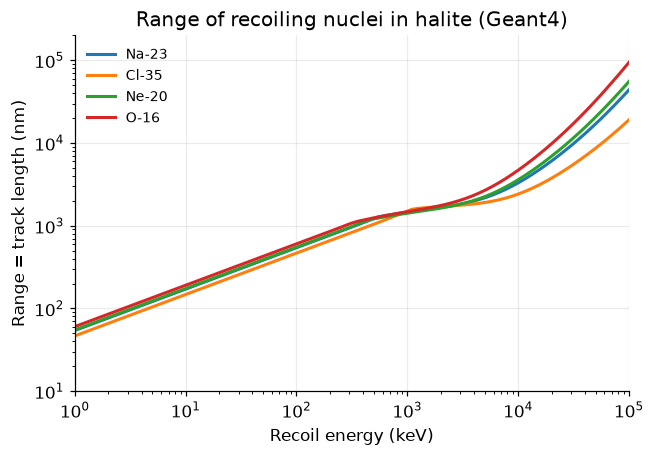

In [16]:
range_dir = Path(pp.data_path()) / "Geant4_data" / "Halite" / "Range"
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for z, a, name in [(11, 23, "Na-23"), (17, 35, "Cl-35"), (10, 20, "Ne-20"), (8, 16, "O-16")]:
    e_mev, dedx_electronic, dedx_nuclear, range_um = np.loadtxt(range_dir / f"DEDX_Z{z}_A{a}.txt", unpack=True)
    ax.loglog(e_mev * 1e3, range_um * 1e3, lw=2, label=name)
ax.set(xlabel="Recoil energy (keV)", ylabel="Range = track length (nm)", xlim=(1, 1e5), ylim=(10, 2e5),
       title="Range of recoiling nuclei in halite (Geant4)")
ax.legend(fontsize=9)
fig.savefig("figures/14_recoil_ranges.png", dpi=200, bbox_inches="tight")
plt.show()